# Model 3: Gaussian Naive Bayes
**PathSnap · UE24CS352A · owner: KKR**

**Task.** Each row is one (GPS fix, candidate road arc) pair. The model predicts the probability that the candidate is the arc the vehicle was really on. For each fix, the highest-scored candidate is its prediction.

**Data (Student folder).**
- `train` (80 trips): model fitting and 5-fold **GroupKFold** cross-validation. Whole trips stay in one fold.
- `student_test` (10 trips): one final evaluation.

Evaluator trips are not used.

**Shared pipeline.** The team's 19 features (`src/features.py`) and evaluation framework (`src/evaluate.py`), the same for every model. Model code: `src/naive_bayes.py`.

In [1]:
import os, sys, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import classification_report

from src import plot_style as ps
from src.config import N_FOLDS, PROCESSED_DIR, SEED
from src.evaluate import (baseline_metrics, baseline_scores, evaluate_predictions, fit_predict, fix_metrics,
                          group_cv, per_1k_fixes_ms, top_candidates, train_fit_metrics)
from src.features import FEATURE_COLUMNS, load_or_build
from src.naive_bayes import CONFIGS, CORR_THRESHOLD

%matplotlib inline
import matplotlib.pyplot as plt
ps.apply_style()
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 4)

## 1. Data

In [2]:
train = load_or_build("train")
test = load_or_build("student_test")
fixes_train = pd.read_parquet(PROCESSED_DIR / "fixes_train.parquet")
fixes_test = pd.read_parquet(PROCESSED_DIR / "fixes_student_test.parquet")

overview = pd.DataFrame({
    "partition": ["train", "student_test"],
    "trips": [train.trip_id.nunique(), test.trip_id.nunique()],
    "GPS fixes": [len(fixes_train), len(fixes_test)],
    "labelled fixes": [int(fixes_train.fix_valid.sum()), int(fixes_test.fix_valid.sum())],
    "candidate rows": [len(train), len(test)],
    "true-arc rows": [int(train.label.sum()), int(test.label.sum())],
})
overview["true-arc share"] = overview["true-arc rows"] / overview["candidate rows"]
print("trips shared between train and student_test:", len(set(train.trip_id) & set(test.trip_id)))
overview

trips shared between train and student_test: 0


,partition,trips,GPS fixes,labelled fixes,candidate rows,true-arc rows,true-arc share
0,train,80,208417,187867,1869589,185298,0.0991
1,student_test,10,19160,19143,209579,19134,0.0913


In [3]:
print(len(FEATURE_COLUMNS), "features:", ", ".join(FEATURE_COLUMNS))
train[["trip_id", "fix_idx", "arc_id", "label"] + FEATURE_COLUMNS].head(6)

19 features: dist_m, dist_minus_min, dist_ratio, cand_rank, n_cand, heading_diff_deg, cos_heading_diff, has_heading, cos_heading_weighted, speed_mps, log_dt_prev, log_dt_next, log_arc_length, t_along, is_two_way, out_degree_v, in_degree_u, prev_nearest_link, next_nearest_link


,trip_id,fix_idx,arc_id,label,dist_m,dist_minus_min,dist_ratio,cand_rank,n_cand,heading_diff_deg,...,speed_mps,log_dt_prev,log_dt_next,log_arc_length,t_along,is_two_way,out_degree_v,in_degree_u,prev_nearest_link,next_nearest_link
0,00000001,0,64973,1,0.7175,0.0000,1.0000,0,3,1.3034,...,43.6294,0.6931,0.6931,5.6845,0.1098,0,1,1,0,1
1,00000001,0,117639,0,15.0112,14.2937,9.3226,1,3,178.7650,...,43.6294,0.6931,0.6931,6.9290,0.5127,0,1,1,0,0
2,00000001,0,2641,0,32.1993,31.4818,19.3304,2,3,1.4323,...,43.6294,0.6931,0.6931,6.0546,1.0000,0,1,1,0,1
3,00000001,1,64973,1,0.2750,0.0000,1.0000,0,2,0.6839,...,46.4510,0.6931,0.6931,5.6845,0.2585,0,1,1,1,1
4,00000001,1,117639,0,15.9516,15.6766,13.2956,1,2,179.2477,...,46.4510,0.6931,0.6931,6.9290,0.4700,0,1,1,0,0
5,00000001,2,64973,1,1.8263,0.0000,1.0000,0,2,3.4973,...,52.2628,0.6931,0.6931,5.6845,0.4266,0,1,1,1,1


## 2. Naive Bayes assumptions vs our features
Gaussian Naive Bayes assumes that, within each class, every feature is Gaussian and independent of the others. The table lists feature pairs with |r| > 0.8 on the training data. Naive Bayes counts that shared evidence more than once.

,feature A,feature B,Pearson r
0,dist_m,dist_minus_min,0.9479
1,heading_diff_deg,cos_heading_diff,-0.9936
2,heading_diff_deg,cos_heading_weighted,-0.9599
3,cos_heading_diff,cos_heading_weighted,0.9563


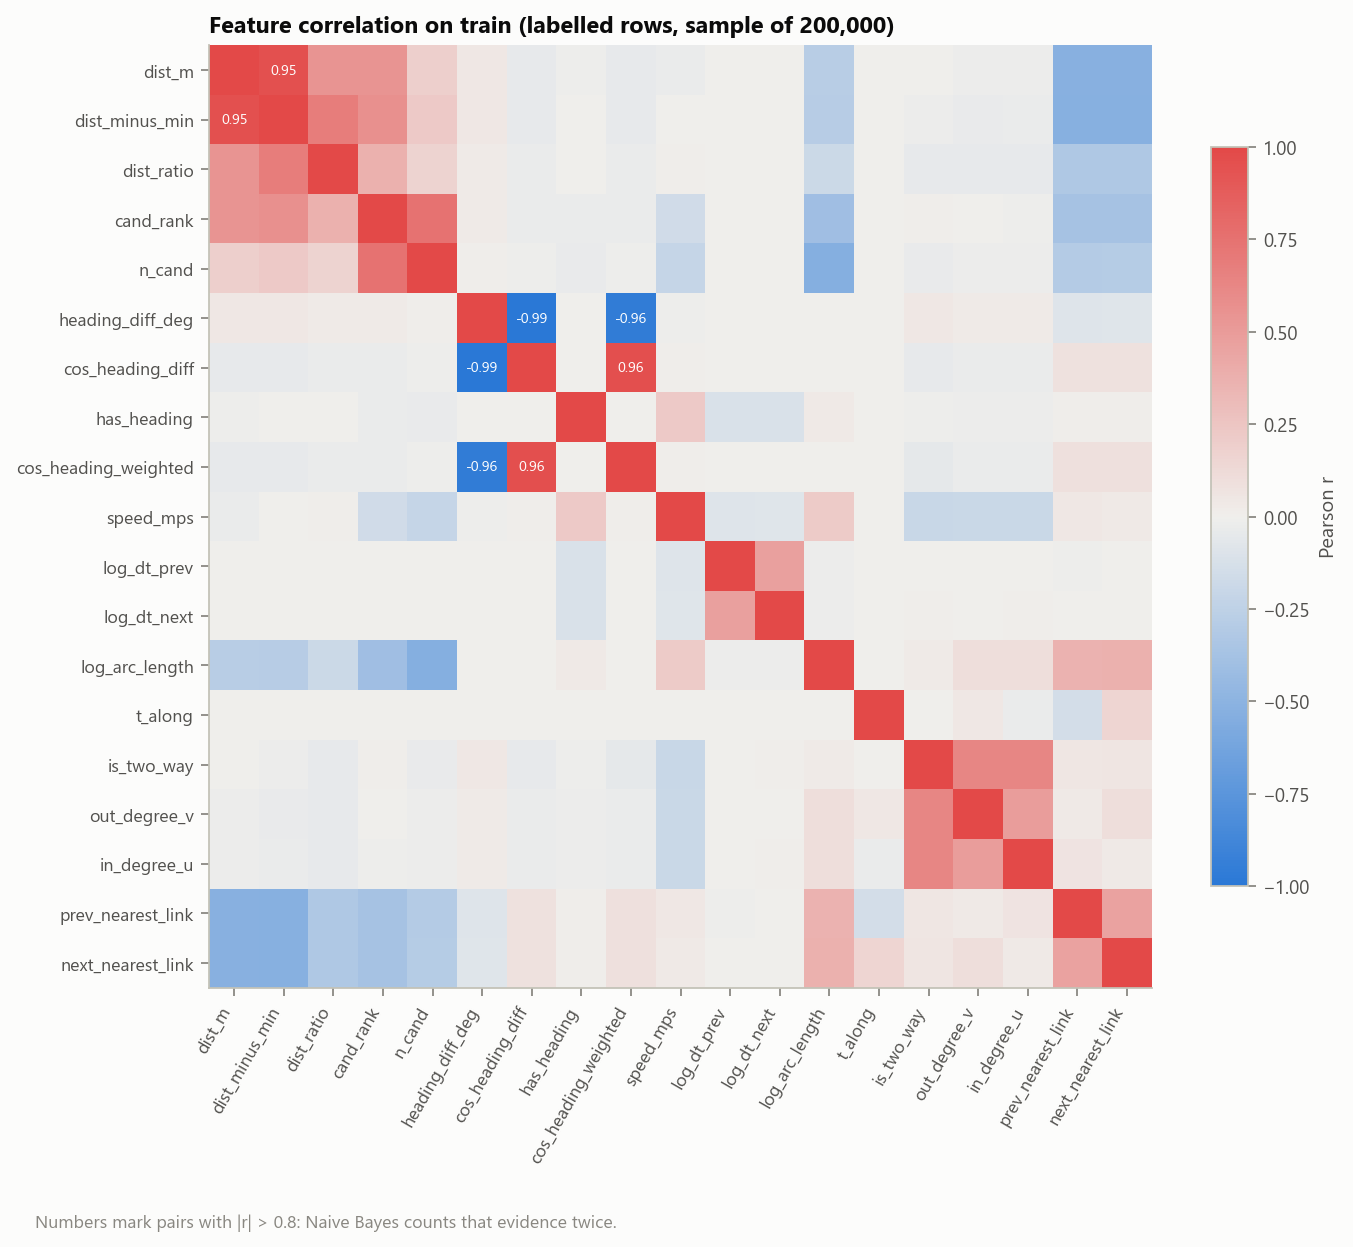

In [4]:
rows = train[train.fix_valid].sample(200_000, random_state=SEED)
corr = rows[FEATURE_COLUMNS].corr()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(FEATURE_COLUMNS) for b in FEATURE_COLUMNS[i + 1:]
         if abs(corr.loc[a, b]) > CORR_THRESHOLD]
display(pd.DataFrame(pairs, columns=["feature A", "feature B", "Pearson r"]))
Image("results/models/naive_bayes/figures/feature_correlation.png", width=720)

## 3. The selected model
Three configurations were compared by cross-validation (section 8). The one with the highest mean CV Top-1 is **`gnb_decorrelated`**:
1. a quantile transform to normal (makes each feature closer to Gaussian)
2. a correlation filter that drops features with |r| > 0.8, fitted inside each training fold
3. `GaussianNB`

student_test was never used to choose it.

In [5]:
NAME = "gnb_decorrelated"
factory, params, desc = CONFIGS[NAME]
print(desc, "| params:", params)
factory(**params)

QuantileTransformer(normal) -> drop |r| > 0.8 -> GaussianNB | params: {'var_smoothing': 1e-09, 'corr_threshold': 0.8}


,steps,"[('quantile', ...), ('decorrelate', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,n_quantiles,1000
,output_distribution,'normal'
,ignore_implicit_zeros,False
,subsample,200000
,random_state,42
,copy,True
,threshold,0.8


## 4. Cross-validation: 5-fold GroupKFold on the 80 train trips

In [6]:
t0 = time.time()
cv = group_cv(factory, params, train, fixes_train, FEATURE_COLUMNS, n_folds=N_FOLDS, seed=SEED, verbose=False)
print(f"cross-validation time: {time.time() - t0:.0f} s")
cols = ["fold", "n_train_trips", "n_val_trips", "n_valid_fixes", "top1", "macro_f1", "accuracy", "precision", "recall",
        "log_loss", "route_continuity", "candidate_miss_rate", "train_macro_f1", "train_time_s", "infer_ms_per_1k_fixes"]
display(cv[cols])
cv[cols[4:]].agg(["mean", "std"])

cross-validation time: 57 s


,fold,n_train_trips,n_val_trips,n_valid_fixes,top1,macro_f1,accuracy,precision,recall,log_loss,route_continuity,candidate_miss_rate,train_macro_f1,train_time_s,infer_ms_per_1k_fixes
0,0,64,16,38578,0.8435,0.8349,0.9351,0.5854,0.8901,0.3971,0.9285,0.0218,0.8110,6.5026,41.5239
1,1,64,16,34197,0.8885,0.8240,0.9156,0.5660,0.9071,0.5244,0.9343,0.0063,0.8143,7.2762,37.2313
2,2,64,16,37002,0.7741,0.7992,0.9064,0.5200,0.8758,0.6701,0.9281,0.0164,0.8223,7.0190,43.1266
3,3,64,16,47166,0.7364,0.7921,0.8949,0.5061,0.8923,0.8101,0.9373,0.0170,0.8250,6.6263,37.5477
4,4,64,16,30924,0.8335,0.8453,0.9340,0.6209,0.8799,0.4044,0.9169,0.0040,0.8135,7.0528,39.2761


,top1,macro_f1,accuracy,precision,recall,log_loss,route_continuity,candidate_miss_rate,train_macro_f1,train_time_s,infer_ms_per_1k_fixes
mean,0.8152,0.8191,0.9172,0.5597,0.8891,0.5612,0.9290,0.0131,0.8172,6.8954,39.7411
std,0.0600,0.0228,0.0175,0.0472,0.0122,0.1780,0.0078,0.0076,0.0061,0.3208,2.5479


## 5. Final model: fit on all 80 train trips, evaluate once on the 10 student_test trips

In [7]:
model, prob, fit_s, pred_s = fit_predict(factory, params, train, test, FEATURE_COLUMNS, seed=SEED)
m = evaluate_predictions(test, prob, fixes_test)
m.update(train_fit_metrics(model, train, FEATURE_COLUMNS, SEED))
m.update({"train_time_s": fit_s, "infer_ms_per_1k_fixes": per_1k_fixes_ms(pred_s, test)})

kept = [FEATURE_COLUMNS[j] for j in model.named_steps["decorrelate"].keep_]
print(f"features kept by the correlation filter: {len(kept)} of {len(FEATURE_COLUMNS)}")
print("dropped:", [f for f in FEATURE_COLUMNS if f not in kept])

keys = ["top1", "macro_f1", "accuracy", "precision", "recall", "log_loss", "route_continuity",
        "candidate_miss_rate", "train_macro_f1", "train_log_loss", "train_time_s", "infer_ms_per_1k_fixes",
        "n_fixes", "n_valid_fixes"]
pd.Series({k: m[k] for k in keys}, name="student_test").to_frame()

features kept by the correlation filter: 15 of 19
dropped: ['dist_ratio', 'cand_rank', 'heading_diff_deg', 'cos_heading_diff']


,student_test
top1,0.8383
macro_f1,0.8145
accuracy,0.9207
precision,0.5394
recall,0.8990
log_loss,0.5177
route_continuity,0.9287
candidate_miss_rate,0.0005
train_macro_f1,0.8179
train_log_loss,0.5676


### Confusion matrix and per-class report (candidate rows of labelled fixes, threshold 0.5)

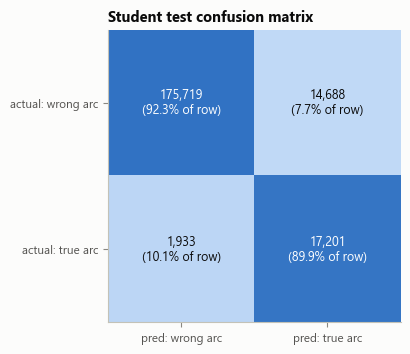

               precision    recall  f1-score   support

wrong arc (0)     0.9891    0.9229    0.9548    190407
 true arc (1)     0.5394    0.8990    0.6742     19134

     accuracy                         0.9207    209541
    macro avg     0.7643    0.9109    0.8145    209541
 weighted avg     0.9481    0.9207    0.9292    209541



In [8]:
valid = test.fix_valid.to_numpy()
y = test.label.to_numpy()[valid]
y_hat = (prob[valid] >= 0.5).astype(int)
cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
labels = ["wrong arc (0)", "true arc (1)"]

fig, ax = plt.subplots(figsize=(4.6, 3.8))
blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#256abf"])
ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap=blues, vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        share = cm[i, j] / cm[i].sum()
        ax.text(j, i, f"{cm[i, j]:,}\n({share:.1%} of row)", ha="center", va="center",
                color="#ffffff" if share > 0.55 else ps.INK, fontsize=9)
ax.set_xticks([0, 1], ["pred: wrong arc", "pred: true arc"])
ax.set_yticks([0, 1], ["actual: wrong arc", "actual: true arc"])
ax.grid(False)
ax.set_title("Student test confusion matrix")
plt.show()
print(classification_report(y, y_hat, target_names=labels, digits=4))

## 6. Against the nearest-road baseline (student_test)

In [9]:
base = baseline_metrics(test, fixes_test)
keys = ["top1", "macro_f1", "precision", "recall", "route_continuity"]
pd.DataFrame({"Nearest-road baseline": {k: base[k] for k in keys},
              "Gaussian NB (gnb_decorrelated)": {k: m[k] for k in keys}})

,Nearest-road baseline,Gaussian NB (gnb_decorrelated)
top1,0.5381,0.8383
macro_f1,0.7459,0.8145
precision,0.5381,0.5394
recall,0.5383,0.8990
route_continuity,0.8210,0.9287


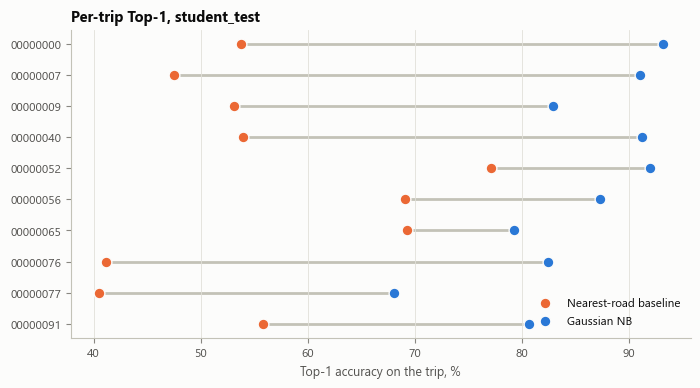

,trip_id,labelled fixes,baseline Top-1,NB Top-1,gain (points)
0,00000000,2503,0.5374,0.9313,39.3927
1,00000007,1354,0.4749,0.9106,43.5746
2,00000009,1049,0.5310,0.8294,29.8379
3,00000040,2995,0.5396,0.9125,37.2955
4,00000052,262,0.7710,0.9198,14.8855
5,00000056,3941,0.6907,0.8726,18.1934
6,00000065,768,0.6927,0.7930,10.0260
7,00000076,1486,0.4112,0.8244,41.3190
8,00000077,3911,0.4050,0.6804,27.5377
9,00000091,874,0.5584,0.8066,24.8284


In [10]:
rows = []
for tid in sorted(test.trip_id.unique()):
    sel = (test.trip_id == tid).to_numpy()
    fx = fixes_test[fixes_test.trip_id == tid]
    rows.append({"trip_id": tid, "labelled fixes": int(fx.fix_valid.sum()),
                 "baseline Top-1": fix_metrics(test[sel], baseline_scores(test[sel]), fx)["top1"],
                 "NB Top-1": fix_metrics(test[sel], prob[sel], fx)["top1"]})
per_trip = pd.DataFrame(rows)
per_trip["gain (points)"] = (per_trip["NB Top-1"] - per_trip["baseline Top-1"]) * 100

fig, ax = plt.subplots(figsize=(8, 4))
yy = np.arange(len(per_trip))
ax.hlines(yy, per_trip["baseline Top-1"] * 100, per_trip["NB Top-1"] * 100, color=ps.BASELINE, lw=2, zorder=1)
ax.scatter(per_trip["baseline Top-1"] * 100, yy, s=60, color=ps.ORANGE, edgecolors=ps.SURFACE, linewidths=1,
           label="Nearest-road baseline", zorder=2)
ax.scatter(per_trip["NB Top-1"] * 100, yy, s=60, color=ps.BLUE, edgecolors=ps.SURFACE, linewidths=1,
           label="Gaussian NB", zorder=3)
ax.set_yticks(yy, per_trip["trip_id"])
ax.invert_yaxis()
ax.set_xlabel("Top-1 accuracy on the trip, %")
ax.set_title("Per-trip Top-1, student_test")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()
per_trip

## 7. What kind of mistakes remain? (labelled student_test fixes)
- *right road, wrong direction*: the chosen arc is the reverse of the true arc (two-way road)
- *wrong road*: the chosen arc is a different road
- *true arc not in candidates*: no candidate within 50 m was the true arc

In [11]:
truth = (test[test.label == 1][["trip_id", "fix_idx", "arc_u", "arc_v"]]
         .drop_duplicates(["trip_id", "fix_idx"]).rename(columns={"arc_u": "tu", "arc_v": "tv"}))
valid_fixes = fixes_test[fixes_test.fix_valid][["trip_id", "fix_idx", "true_in_cands"]]

def outcome_shares(scores):
    top = top_candidates(test, scores)[["trip_id", "fix_idx", "arc_u", "arc_v", "label"]]
    d = valid_fixes.merge(top, on=["trip_id", "fix_idx"], how="left").merge(truth, on=["trip_id", "fix_idx"], how="left")
    kind = np.select([d["label"] == 1, ~d["true_in_cands"].astype(bool), (d["arc_u"] == d["tv"]) & (d["arc_v"] == d["tu"])],
                     ["correct", "true arc not in candidates", "right road, wrong direction"], "wrong road")
    return pd.Series(kind).value_counts(normalize=True)

order = ["correct", "right road, wrong direction", "wrong road", "true arc not in candidates"]
pd.DataFrame({"Nearest-road baseline": outcome_shares(baseline_scores(test)),
              "Gaussian NB": outcome_shares(prob)}).reindex(order).fillna(0).style.format("{:.1%}")

,Nearest-road baseline,Gaussian NB
correct,53.8%,83.8%
"right road, wrong direction",35.3%,6.8%
wrong road,10.9%,9.3%
true arc not in candidates,0.1%,0.1%


## 8. All three Naive Bayes configurations (from `python -m src.naive_bayes`)

,config,description,cv_macro_f1_mean,cv_macro_f1_std,cv_top1_mean,cv_top1_std,cv_log_loss_mean,cv_train_macro_f1_mean,st_macro_f1,st_top1,st_log_loss,st_route_continuity,infer_ms_per_1k_fixes
0,gnb_all,GaussianNB on all 19 raw features,0.8048,0.0116,0.8021,0.0515,0.5800,0.8049,0.8038,0.8130,0.5215,0.9431,5.6709
1,gnb_quantile,QuantileTransformer(normal) -> GaussianNB,0.8190,0.0219,0.7732,0.0822,0.7425,0.8177,0.8165,0.7946,0.6799,0.8991,29.1826
2,gnb_decorrelated,QuantileTransformer(normal) -> drop |r| > 0.8 ...,0.8191,0.0228,0.8152,0.0600,0.5612,0.8172,0.8145,0.8383,0.5177,0.9287,26.7871


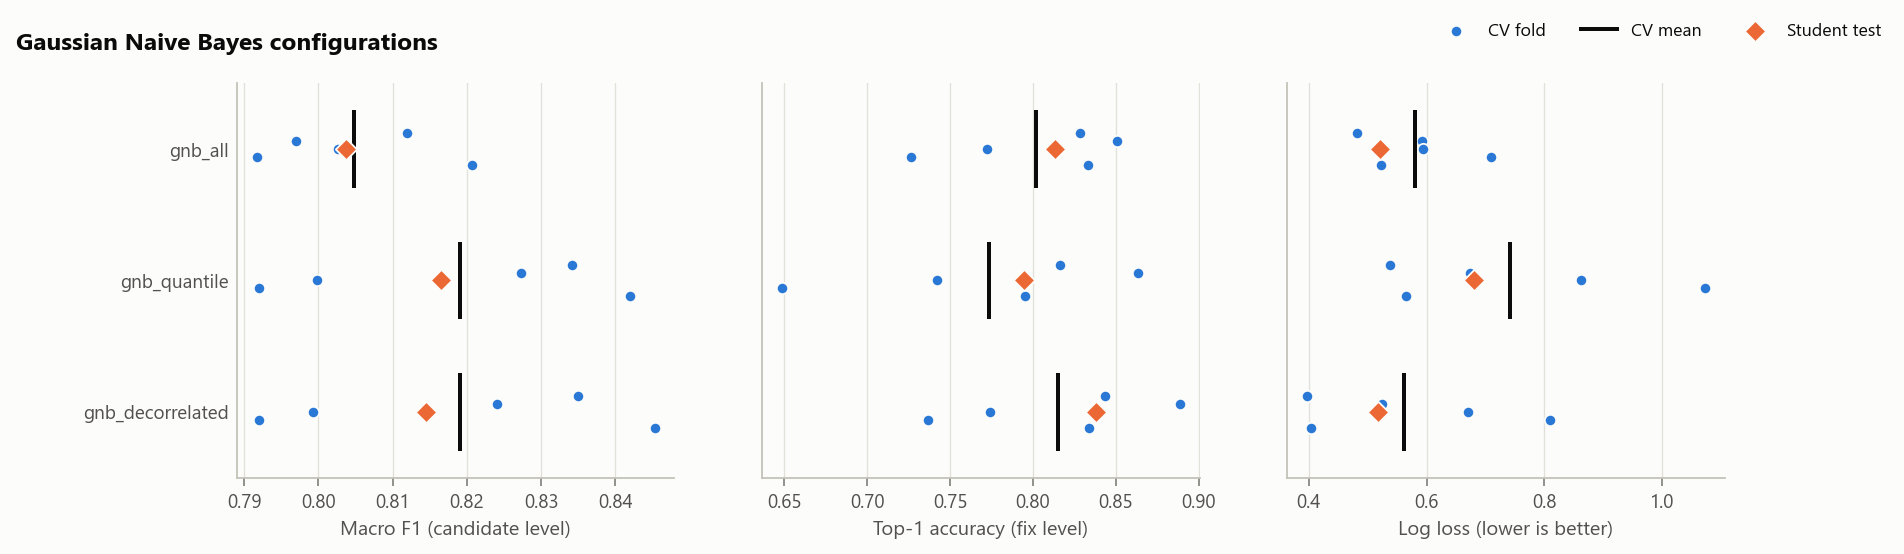

In [12]:
summary = pd.read_csv("results/models/naive_bayes/summary.csv")
display(summary[["config", "description", "cv_macro_f1_mean", "cv_macro_f1_std", "cv_top1_mean", "cv_top1_std",
                 "cv_log_loss_mean", "cv_train_macro_f1_mean", "st_macro_f1", "st_top1", "st_log_loss",
                 "st_route_continuity", "infer_ms_per_1k_fixes"]])
Image("results/models/naive_bayes/figures/nb_configurations.png", width=900)

## 9. Over/underfitting check: training-fold vs held-out macro F1

In [13]:
fit_check = cv[["fold", "train_macro_f1", "macro_f1"]].rename(columns={"macro_f1": "held_out_macro_f1"})
fit_check["gap"] = fit_check["train_macro_f1"] - fit_check["held_out_macro_f1"]
display(fit_check)
print(f"mean train macro F1 {fit_check.train_macro_f1.mean():.4f} | mean held-out macro F1 "
      f"{fit_check.held_out_macro_f1.mean():.4f} | mean gap {fit_check.gap.mean():+.4f}")

,fold,train_macro_f1,held_out_macro_f1,gap
0,0,0.8110,0.8349,-0.0239
1,1,0.8143,0.8240,-0.0097
2,2,0.8223,0.7992,0.0231
3,3,0.8250,0.7921,0.0329
4,4,0.8135,0.8453,-0.0318


mean train macro F1 0.8172 | mean held-out macro F1 0.8191 | mean gap -0.0019


## 10. Key numbers

In [14]:
key = pd.Series({
    "CV macro F1 (mean ± std)": f"{cv.macro_f1.mean():.4f} ± {cv.macro_f1.std():.4f}",
    "CV Top-1 (mean ± std)": f"{cv.top1.mean():.1%} ± {cv.top1.std() * 100:.1f} pts",
    "CV log loss (mean)": f"{cv.log_loss.mean():.4f}",
    "Student-test Top-1": f"{m['top1']:.1%}",
    "Student-test macro F1": f"{m['macro_f1']:.4f}",
    "Student-test log loss": f"{m['log_loss']:.4f}",
    "Student-test route continuity (classifier only)": f"{m['route_continuity']:.1%}",
    "Nearest-road baseline Top-1 (student test)": f"{base['top1']:.1%}",
    "Training time (all 80 trips)": f"{m['train_time_s']:.1f} s",
    "Inference time": f"{m['infer_ms_per_1k_fixes']:.1f} ms per 1,000 fixes",
}, name="Gaussian NB (gnb_decorrelated)")
key.to_frame()

,Gaussian NB (gnb_decorrelated)
CV macro F1 (mean ± std),0.8191 ± 0.0228
CV Top-1 (mean ± std),81.5% ± 6.0 pts
CV log loss (mean),0.5612
Student-test Top-1,83.8%
Student-test macro F1,0.8145
Student-test log loss,0.5177
Student-test route continuity (classifier only),92.9%
Nearest-road baseline Top-1 (student test),53.8%
Training time (all 80 trips),7.9 s
Inference time,"46.1 ms per 1,000 fixes"
